# Optics matching with Bayesian optimization

We first track a beam through a FODO lattice, then use **BoTorch** to find periodic Twiss parameters. Each objective evaluation runs RF-Track; a Gaussian process learns from those evaluations and proposes the next trial.

This notebook requires RF-Track, NumPy, Matplotlib, PyTorch, and BoTorch (which installs GPyTorch). If needed, run `%pip install botorch` in a separate notebook cell, then restart the kernel. See the [BoTorch getting-started example](https://botorch.org/) for the underlying API.

At the end we compare the result with `scipy.minimize`, first on the simulated beam and then with measurement noise, as on a real machine.

In [1]:
import os
from time import perf_counter
import RF_Track as rft
import numpy as np
import matplotlib.pyplot as plt


RF-Track, version 2.7.3

Copyright (C) 2016-2026 CERN, Geneva, Switzerland. All rights reserved.

Author and contact:
 Andrea Latina <andrea.latina@cern.ch>
 BE-ABP Group
 CERN
 CH-1211 GENEVA 23
 SWITZERLAND

This software is distributed under a CERN proprietary software
license in the hope that it will be useful, but WITHOUT ANY WARRANTY;
not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

See the COPYRIGHT and LICENSE files at the top-level directory of
the RF-Track download area: https://gitlab.cern.ch/rf-track

RF-Track was compiled with GSL-2.8 and fftw-3.3.11



[RF-Track] Could not check for updates.


## Bunch parameters

In [2]:
# Bunch parameters
mass = rft.electronmass # MeV/c^2
charge = -1 # single-particle charge, in units of e
population = 1*rft.nC # number of real particles per bunch
Pc = 5 # reference momentum, MeV/c
P_Q = Pc / charge # MV/c, reference rigidity

## FODO cell parameters

In [3]:
# FODO cell parameters
Lcell = 2 # m
Lquad = 0.2 # m
Ldrift = Lcell/2 - Lquad # m

mu = np.deg2rad(90) # deg
k1L = np.sin(mu/2) / (Lcell/4) # 1/m

strength = k1L * P_Q # MeV/m

In [4]:
print(strength)

-7.071067811865475


## Define the elements

In [5]:
# Half a focusing quadrupole

Qf = rft.Quadrupole(Lquad/2, strength/2)
Qf.set_tt_nsteps(10)

# A full, defocusing, quadrupole
QD = rft.Quadrupole(Lquad, -strength)
QD.set_tt_nsteps(20)

# The Drift
Dr = rft.Drift(Ldrift)
Dr.set_tt_nsteps(100)

# Define a lattice with 10 FODO cells

In [6]:
# Define the FODO cell
FODO = rft.Lattice()
FODO.append(Qf)
FODO.append(Dr)
FODO.append(QD)
FODO.append(Dr)
FODO.append(Qf)

# Create the full lattice by repeating the FODO cell 10 times
L = rft.Lattice()
for _ in range(10):
    L.append(FODO)

# ...and a bunch

In [7]:
# Define Twiss parameters
Twiss = rft.Bunch6d_twiss()
Twiss.emitt_x = 0.001 # mm.mrad, normalized emittances
Twiss.emitt_y = 0.001 # mm.mrad
Twiss.alpha_x = 0.0
Twiss.alpha_y = 0.0
Twiss.beta_x = Lcell * (1 + np.sin(mu/2)) / np.sin(mu) # m
Twiss.beta_y = Lcell * (1 - np.sin(mu/2)) / np.sin(mu) # m

# Create the bunch
B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)

In [8]:
print(Twiss.beta_x)
print(Twiss.beta_y)

3.414213562373095
0.5857864376269051


# Then, we can perform tracking

In [9]:
L.set_tt_nsteps(1000)
B1 = L.track(B0)

We can query the lattice to obtain, for example, the Twiss parameters and emittance.

In [10]:
T = L.get_transport_table('%S %beta_x %beta_y %emitt_x %emitt_y %sigma_x %sigma_y');

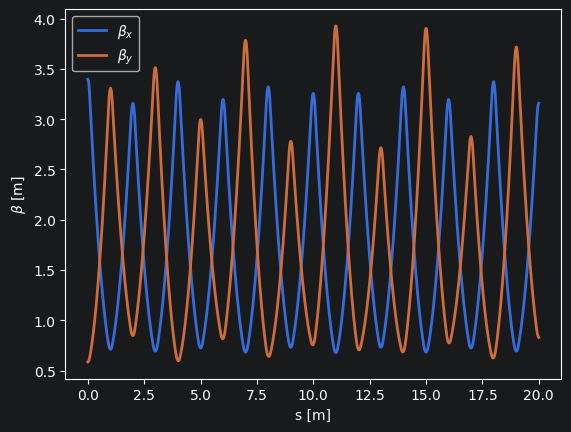

In [11]:
plt.plot(T[:,0], T[:,1], linewidth=2, label=r'$\beta_x$')
plt.plot(T[:,0], T[:,2], linewidth=2, label=r'$\beta_y$')
plt.legend()
plt.xlabel('s [m]')
plt.ylabel(r'$\beta$ [m]')
plt.show()

# Now we can match the Twiss parameters to be periodic
## Start with defining a merit function
This function returns zero when the initial and final beta functions are equal and the initial and final alpha functions are equal:
\begin{align*}
\chi^{2}= & \left(\beta_{x,\text{ final}}-\beta_{x,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\beta_{y,\text{ final}}-\beta_{y,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\alpha_{x,\text{ final}}-\alpha_{x,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\alpha_{y,\text{ final}}-\alpha_{y,\text{ initial}}\right)^{2}
\end{align*}

We keep this simple merit function for continuity with the optics example. It combines beta differences in metres with dimensionless alpha differences, so its relative weights implicitly depend on that choice of units. A production matching problem should scale each residual by a chosen tolerance.

In [12]:
def match_Twiss(twiss, FODO, noise=0.0, return_residuals=False):

    beta_x = twiss[0] # m
    beta_y = twiss[1] # m
    alpha_x = twiss[2]
    alpha_y = twiss[3]

    # Create a bunch with initial beta_x and beta_y from 'twiss'
    Twiss = rft.Bunch6d_twiss()
    Twiss.emitt_x = 0.001 # mm.mrad, normalized emittances
    Twiss.emitt_y = 0.001 # mm.mrad
    Twiss.beta_x = beta_x # m
    Twiss.beta_y = beta_y # m
    Twiss.alpha_x = alpha_x #
    Twiss.alpha_y = alpha_y #

    # Create the bunch
    B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)

    # Perform tracking
    B1 = FODO.track(B0)
    I1 = B1.get_info()

    # Final minus initial Twiss parameters, plus an optional measurement error
    residuals = np.array([I1.beta_x - beta_x,
                          I1.beta_y - beta_y,
                          I1.alpha_x - alpha_x,
                          I1.alpha_y - alpha_y])
    residuals += np.random.normal(scale=noise, size=4)
    return residuals if return_residuals else np.sum(residuals ** 2) # M = merit function

## An initial guess from two test particles

Before running the optimizer, we calculate the Twiss parameters that repeat after one FODO cell. This gives us an independent reference for checking the optimization result.

In linear, uncoupled optics, a particle's final position and angle depend on its starting position and angle:

$$
\begin{aligned} x_f &= R_{11}x_0 + R_{12}x'_0, \\ x'_f &= R_{21}x_0 + R_{22}x'_0. \end{aligned}
$$

In matrices below, positions are in **mm** and angles in **mrad**.

**Particle 1 - position only:** $x_0=1\,\mathrm{mm}$ and $x'_0=0$.

$$
\begin{pmatrix}x_f^{(1)}\\x_f^{\prime(1)}\end{pmatrix} = \begin{pmatrix}R_{11}&R_{12}\\R_{21}&R_{22}\end{pmatrix}\begin{pmatrix}1\\0\end{pmatrix} = \begin{pmatrix}R_{11}\cdot1+R_{12}\cdot0\\R_{21}\cdot1+R_{22}\cdot0\end{pmatrix} = \begin{pmatrix}R_{11}\\R_{21}\end{pmatrix}.
$$

The zero angle removes the second column's values. Tracking gives the first column of $R$.

**Particle 2 - angle only:** $x_0=0$ and $x'_0=1\,\mathrm{mrad}$.

$$
\begin{pmatrix}x_f^{(2)}\\x_f^{\prime(2)}\end{pmatrix} = \begin{pmatrix}R_{11}&R_{12}\\R_{21}&R_{22}\end{pmatrix}\begin{pmatrix}0\\1\end{pmatrix} = \begin{pmatrix}R_{11}\cdot0+R_{12}\cdot1\\R_{21}\cdot0+R_{22}\cdot1\end{pmatrix} = \begin{pmatrix}R_{12}\\R_{22}\end{pmatrix}.
$$

The zero position removes the first column's values. Tracking gives the second column of $R$.

We repeat this for $y$: **four test particles in total**. They determine the lattice response, so we do not need to estimate it from a large bunch.

For this stable FODO cell, $R$ gives the phase advance $\mu$ and the periodic Twiss parameters:

$$
\cos\mu=\frac{R_{11}+R_{22}}{2},\qquad \beta=\frac{R_{12}}{\sin\mu},\qquad \alpha=\frac{R_{11}-R_{22}}{2\sin\mu}.
$$

We use this solution only as a reference. The optimizers still evaluate the matching merit by tracking a 1000-particle bunch.

In [13]:
bx = np.array([
    [1.0, 0.0, 0.0, 0.0, 0.0, Pc],
    [0.0, 1.0, 0.0, 0.0, 0.0, Pc],
], dtype=float)

bunch_x = rft.Bunch6d(mass, 0.0, charge, bx)
tracked_x = FODO.track(bunch_x)
phase_space_x = np.asarray(tracked_x.get_phase_space("%x %xp"), dtype=float)

R11 = float(phase_space_x[0, 0])
R12 = float(phase_space_x[1, 0])
R21 = float(phase_space_x[0, 1])
R22 = float(phase_space_x[1, 1])

by = np.array([
    [0.0, 0.0, 1.0, 0.0, 0.0, Pc],
    [0.0, 0.0, 0.0, 1.0, 0.0, Pc],
], dtype=float)

bunch_y = rft.Bunch6d(mass, 0.0, charge, by)
tracked_y = FODO.track(bunch_y)
phase_space_y = np.asarray(tracked_y.get_phase_space("%y %yp"), dtype=float)

R33 = float(phase_space_y[0, 0])
R34 = float(phase_space_y[1, 0])
R43 = float(phase_space_y[0, 1])
R44 = float(phase_space_y[1, 1])

Rx = np.array([[R11, R12],
               [R21, R22]])
Ry = np.array([[R33, R34],
               [R43, R44]])

def periodic_Twiss(R):
    mu = np.arccos((R[0,0] + R[1,1]) / 2)
    return R[0,1] / np.sin(mu), (R[0,0] - R[1,1]) / (2 * np.sin(mu)), np.rad2deg(mu)

beta_x0, alpha_x0, mu_x = periodic_Twiss(Rx)
beta_y0, alpha_y0, mu_y = periodic_Twiss(Ry)
exact_twiss = np.array([beta_x0, beta_y0, alpha_x0, alpha_y0])
merit_floor = match_Twiss(exact_twiss, FODO)

print(f"Phase advance per cell: mu_x = {mu_x:.1f} deg, mu_y = {mu_y:.1f} deg")
print(f"Solution: beta_x = {beta_x0:.4f} m, beta_y = {beta_y0:.4f} m, alpha_x = {alpha_x0:.1e}, alpha_y = {alpha_y0:.1e}")
print(f"Merit of the exact solution with a 1000-particle bunch: {merit_floor:.1e}")

Phase advance per cell: mu_x = 82.3 deg, mu_y = 82.3 deg
Solution: beta_x = 3.2715 m, beta_y = 0.7049 m, alpha_x = 4.2e-16, alpha_y = 1.6e-15
Merit of the exact solution with a 1000-particle bunch: 7.0e-04


## Bayesian optimization: learn, propose, evaluate

BoTorch maximizes an objective. The merit $M$ varies over many orders of magnitude in the search box, which makes it hard to learn with a Gaussian process. We therefore model the four residuals instead, one Gaussian process each: they are almost linear functions of the initial Twiss parameters. BoTorch then computes $-M=-\sum_i r_i^2$ from samples of this model.

We search the same box as the SciPy example, keeping $\beta>0$. At each iteration, only the point with the largest log expected improvement is tracked with RF-Track.

In [14]:
import warnings
import torch
from botorch.models import SingleTaskGP
from botorch.models.transforms.outcome import Standardize
from botorch.fit import fit_gpytorch_mll
from botorch.acquisition.logei import qLogExpectedImprovement
from botorch.acquisition.objective import GenericMCObjective
from botorch.optim import optimize_acqf
from botorch.utils.transforms import normalize, unnormalize
from gpytorch.mlls import ExactMarginalLogLikelihood
from gpytorch.utils.warnings import NumericalWarning

warnings.filterwarnings("ignore", message="Very small noise values detected", category=NumericalWarning)
warnings.filterwarnings("ignore", message=r"(?s)Optimization failed in `gen_candidates_scipy`.*Trying again with a new set of initial conditions\.", category=RuntimeWarning)

# Double precision is recommended for Gaussian processes; RF-Track runs on CPU.
dtype = torch.double
device = torch.device("cpu")
seed = 42

# Columns: beta_x [m], beta_y [m], alpha_x, alpha_y; beta > 0.
bounds = torch.tensor([[0.01, 0.01, -5.0, -5.0],
                       [10.0, 10.0,  5.0,  5.0]], dtype=dtype, device=device)
unit_bounds = torch.stack([torch.zeros(4), torch.ones(4)]).to(bounds)
initial_guess = torch.tensor([
    Lcell * (1 + np.sin(mu/2)) / np.sin(mu),
    Lcell * (1 - np.sin(mu/2)) / np.sin(mu),
    0.0, 0.0
], dtype=dtype, device=device)

n_initial = 8  # includes the thin-lens estimate
n_iterations = 40  # one new RF-Track evaluation per iteration

# BoTorch maximizes: minus the merit, computed from (samples of) the modelled residuals
merit_objective = GenericMCObjective(lambda R, X=None: -(R ** 2).sum(dim=-1))

def evaluate_residuals(X, noise):
    """Map normalized inputs (n, 4) to RF-Track residuals (n, 4)."""
    physical_twiss = unnormalize(X, bounds).detach().cpu().numpy()
    values = [match_Twiss(twiss, FODO, noise, return_residuals=True) for twiss in physical_twiss]
    return torch.tensor(np.array(values), dtype=dtype, device=device)

### Fit the model and select the next experiment

`SingleTaskGP` models the four residuals. The QR bunch construction is deterministic here; a small observation variance, fixed relative to the variance of each residual, provides numerical regularization. When the measurements are noisy, we add their known variance, `noise**2`.

`qLogExpectedImprovement` estimates the expected improvement of $-M$ from samples of the residual model. With `q=1`, we propose one experiment at a time.

In [15]:
def bayesian_matching(noise=0.0):
    torch.manual_seed(seed)
    sobol = torch.quasirandom.SobolEngine(dimension=4, scramble=True, seed=seed)
    train_X = torch.cat([normalize(initial_guess, bounds).unsqueeze(0), sobol.draw(n_initial - 1).to(bounds)])
    train_R = evaluate_residuals(train_X, noise)

    for iteration in range(n_iterations):
        # 1. Learn the residuals from all evaluations so far.
        model = SingleTaskGP(
            train_X, train_R,
            train_Yvar=torch.full_like(train_R, noise**2) + 1e-6 * train_R.var(dim=0),
            outcome_transform=Standardize(m=4),
        )
        mll = ExactMarginalLogLikelihood(model.likelihood, model)
        fit_gpytorch_mll(mll)

        # 2. Find the most promising next input using the cheap surrogate.
        acquisition = qLogExpectedImprovement(model, best_f=merit_objective(train_R).max(),
                                              objective=merit_objective)
        candidate, _ = optimize_acqf(
            acquisition, bounds=unit_bounds, q=1,
            num_restarts=10, raw_samples=512,
        )
        candidate = candidate.detach()

        # 3. Run the actual tracking experiment, then append its result.
        train_X = torch.cat([train_X, candidate])
        train_R = torch.cat([train_R, evaluate_residuals(candidate, noise)])

    # Use the best point actually tracked, rather than the surrogate's prediction.
    train_M = (train_R ** 2).sum(dim=-1)
    best_twiss = unnormalize(train_X[train_M.argmin()], bounds).cpu().numpy()
    return best_twiss, train_M.cpu().numpy(), unnormalize(train_X, bounds).cpu().numpy()


start_time = perf_counter()
matched_twiss, merit_history, _ = bayesian_matching()
print(f"BoTorch time: {perf_counter() - start_time:.3f} s")
print("Matched [beta_x, beta_y, alpha_x, alpha_y]:", matched_twiss)
print(f"Merit: {merit_history[0]:.6g} -> {merit_history.min():.6g}")
print(f"Total tracking evaluations: {len(merit_history)}")

/Users/wiktoriamalek/Developer/flight-simulator-repositories/jupyter-notebooks/.venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed on the second try, after generating a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/wiktoriamalek/Developer/flight-simulator-repositories/jupyter-notebooks/.venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed on the second try, after generating a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


BoTorch time: 29.178 s
Matched [beta_x, beta_y, alpha_x, alpha_y]: [3.28055500e+00 7.05829187e-01 1.40317656e-03 9.32279651e-03]
Merit: 0.135161 -> 1.28702e-09
Total tracking evaluations: 48


### Comparison with SciPy

A fixed evaluation budget is a stopping rule, not a convergence guarantee. For comparison, we repeat the SciPy matching of pyTutorial_04 with the same bounds and initial guess, recording every tracking run.

The dashed line is the merit of the exact solution: below it, an optimizer only fits the statistical error of the 1000-particle bunch. The relevant question is therefore how many tracking runs each method needs to reach this line.

In [16]:
from scipy.optimize import minimize

scipy_bounds = [(0.01, 10), (0.01, 10), (-5, 5), (-5, 5)]

def scipy_matching(noise=0.0):
    history = []
    points = []
    def merit(twiss):
        history.append(match_Twiss(twiss, FODO, noise))
        points.append(twiss.copy())
        return history[-1]
    result = minimize(merit, initial_guess.cpu().numpy(), bounds=scipy_bounds)
    return result.x, np.array(history), np.array(points)

start_time = perf_counter()
scipy_twiss, scipy_history, _ = scipy_matching()
print(f"SciPy time: {perf_counter() - start_time:.3f} s")
print(f"SciPy: best merit {scipy_history.min():.3g} after {len(scipy_history)} tracking evaluations")

SciPy time: 2.242 s
SciPy: best merit 1.42e-11 after 45 tracking evaluations


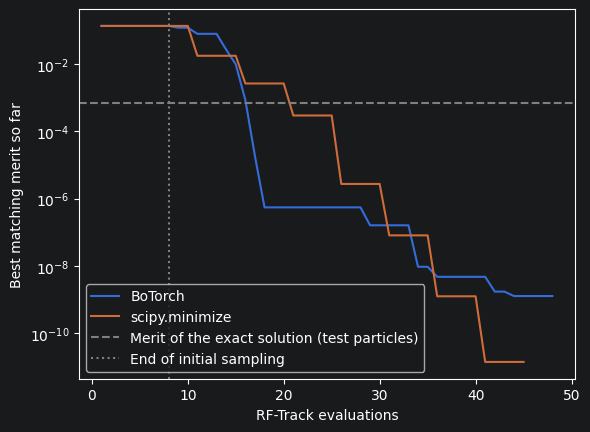

In [17]:
plt.semilogy(np.arange(1, len(merit_history) + 1), np.minimum.accumulate(merit_history), label="BoTorch")
plt.semilogy(np.arange(1, len(scipy_history) + 1), np.minimum.accumulate(scipy_history), label="scipy.minimize")
plt.axhline(merit_floor, color="grey", linestyle="--", label="Merit of the exact solution (test particles)")
plt.axvline(n_initial, color="grey", linestyle=":", label="End of initial sampling")
plt.xlabel("RF-Track evaluations")
plt.ylabel("Best matching merit so far")
plt.legend(loc="lower left")
plt.show()

Let's create a beam with the best observed Twiss parameters

In [18]:
Twiss.beta_x = matched_twiss[0]
Twiss.beta_y = matched_twiss[1]
Twiss.alpha_x = matched_twiss[2]
Twiss.alpha_y = matched_twiss[3]

# Create the bunch
B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)

In [19]:
# A periodic beam has the same Twiss parameters after one complete cell.
matched_info = FODO.track(B0).get_info()
final_twiss = np.array([matched_info.beta_x, matched_info.beta_y,
                        matched_info.alpha_x, matched_info.alpha_y])
for name, start, end in zip(["beta_x [m]", "beta_y [m]", "alpha_x", "alpha_y"],
                            matched_twiss, final_twiss):
    print(f"{name:12s}: initial={start: .6f}, final={end: .6f}, residual={end-start: .3e}")
print("Difference from the exact solution (test particles):", np.round(matched_twiss - exact_twiss, 4))

beta_x [m]  : initial= 3.280555, final= 3.280547, residual=-7.828e-06
beta_y [m]  : initial= 0.705829, final= 0.705826, residual=-2.873e-06
alpha_x     : initial= 0.001403, final= 0.001438, residual= 3.476e-05
alpha_y     : initial= 0.009323, final= 0.009320, residual=-3.060e-06
Difference from the exact solution (test particles): [0.0091 0.0009 0.0014 0.0093]


In [20]:
B1 = L.track(B0)

In [21]:
T = L.get_transport_table('%S %beta_x %beta_y %emitt_x %emitt_y %sigma_x %sigma_y')

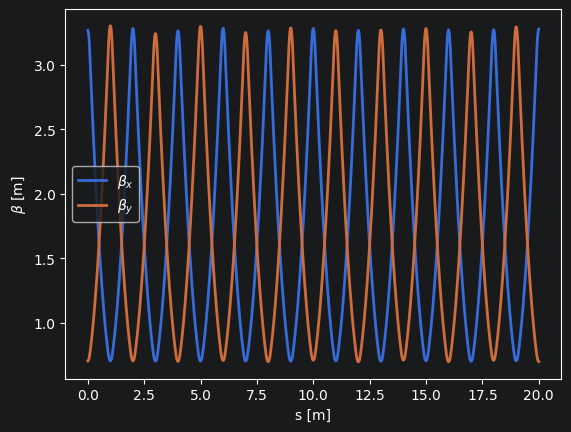

In [22]:
plt.plot(T[:,0], T[:,1], linewidth=2, label=r'$\beta_x$')
plt.plot(T[:,0], T[:,2], linewidth=2, label=r'$\beta_y$')
plt.legend()
plt.xlabel('s [m]')
plt.ylabel(r'$\beta$ [m]')
plt.show()

# Why Bayesian optimization? Noisy measurements

On a real accelerator the Twiss parameters are measured, and every measurement has an error. We imitate this with `noise = 0.01`: a random error of 1 cm on each beta function and of 0.01 on each alpha function, different at every evaluation.

`scipy.minimize` estimates gradients from tiny finite differences The Gaussian process instead averages the noise over many evaluations. The merit is now noisy too, so we judge both results by their distance from the exact solution computed with the test particles.

In [23]:
noise = 0.01

start_time = perf_counter()
bo_twiss_noisy, bo_history_noisy, bo_points_noisy = bayesian_matching(noise)
print(f"BoTorch time (noise={noise}): {perf_counter() - start_time:.3f} s")
start_time = perf_counter()
scipy_twiss_noisy, scipy_history_noisy, scipy_points_noisy = scipy_matching(noise)
print(f"SciPy time (noise={noise}): {perf_counter() - start_time:.3f} s")

print("Difference from the exact solution [beta_x, beta_y, alpha_x, alpha_y]:")
print("  BoTorch:         ", np.round(bo_twiss_noisy - exact_twiss, 4), f"after {len(bo_history_noisy)} evaluations")
print("  SciPy:           ", np.round(scipy_twiss_noisy - exact_twiss, 4), f"after {len(scipy_history_noisy)} evaluations")

/Users/wiktoriamalek/Developer/flight-simulator-repositories/jupyter-notebooks/.venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed on the second try, after generating a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/wiktoriamalek/Developer/flight-simulator-repositories/jupyter-notebooks/.venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed on the second try, after generating a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/wiktoriamalek/Developer/flight-simulator-repositories/jupyter-notebooks/.venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed on the second try, after generating a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/wiktoriamalek/Developer/flight-simulator-repositories/jupyter-notebooks/.venv/lib/py

BoTorch time (noise=0.01): 25.890 s
SciPy time (noise=0.01): 6.090 s
Difference from the exact solution [beta_x, beta_y, alpha_x, alpha_y]:
  BoTorch:          [0.0082 0.0009 0.0026 0.0089] after 48 evaluations
  SciPy:            [ 0.1427 -0.1192 -0.      0.    ] after 120 evaluations


### Conclusions

Without noise, and with a simulation this cheap, SciPy is actually the better choice here. It needs a similar number of tracking runs to reach the statistical precision of the 1000-particle bunch. Bayesian optimization is better when:

* each evaluation is expensive (a measurement on the machine, or a long simulation),
* the measurement is noisy,
* there is no good initial guess.
As you can see, with added noise, scipy behaves in a worse way, with a larger cost of evaluation.
One could play with the noise to see the advantage of BO.

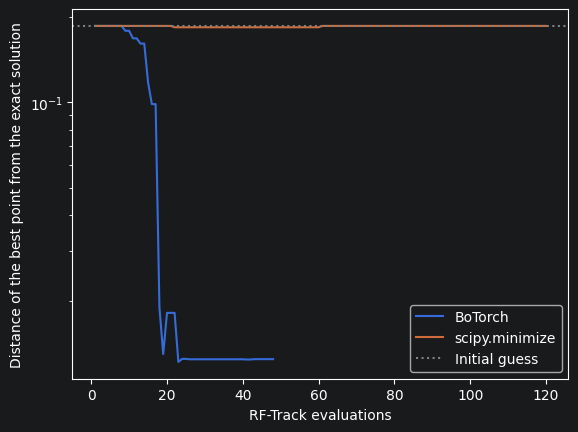

In [24]:
def best_distance(points, merits):
    # Distance from the exact solution of the best point so far
    return [np.linalg.norm(points[np.argmin(merits[:k])] - exact_twiss) for k in range(1, len(merits) + 1)]

plt.semilogy(range(1, len(bo_history_noisy) + 1), best_distance(bo_points_noisy, bo_history_noisy), label="BoTorch")
plt.semilogy(range(1, len(scipy_history_noisy) + 1), best_distance(scipy_points_noisy, scipy_history_noisy), label="scipy.minimize")
plt.axhline(np.linalg.norm(initial_guess.cpu().numpy() - exact_twiss), color="grey", linestyle=":", label="Initial guess")
plt.xlabel("RF-Track evaluations")
plt.ylabel("Distance of the best point from the exact solution")
plt.legend()
plt.show()

# Exercises

## Exercise 1 — Explore Bayesian optimization sensitivity

Repeat the optimization with different Sobol seeds, initial sample counts, and iteration budgets. Rerun from the settings cell so that each run starts with fresh data. Compare the best merit against the number of RF-Track evaluations. Does a larger budget reliably improve the match? How much do the results vary with the seed?

Widen the search bounds and compare the result at the same evaluation budget. Why does prior knowledge of a plausible optics range help? Compare modeling `-train_M` directly with `-torch.log10(train_M + 1e-8)` (change both score assignments).

Finally, add a penalty $\lambda(\beta_x^2+\beta_y^2)$ to the merit function and investigate the compromise between periodicity and beam size. Report the unpenalized periodicity residual as well as the penalized objective.

In [25]:
# Your solution